# Magnetic-dipole meta-atom

Design a meta-atom with the strongest magnetic dipole.

**Question.** A plane wave of vacuum wavelength 1 µm lights a cube of side 0.35 µm, smaller
than the wavelength, in air. Where should a lossless high-index material
($\varepsilon_r = 12.25$, silicon without loss) sit in the cube to scatter the strongest
magnetic dipole? The measure is the absolute {term}`partial scattering cross section` of the
magnetic dipole, $\sigma^M_1$ in µm², the share of the incident power that
the magnetic dipole radiates, per unit of incident intensity.

We let gradients find it, as in the {doc}`metagrating tutorial <metagrating>`. The chain from
the design to the objective is differentiable end to end:

density $\rho$, one value per element of the cube → **Helmholtz filter** → **projection**
→ **material field** $\varepsilon_r$ → {py:func}`gfem.solve` → {py:func}`gfem.multipoles`
→ $-\sigma^M_1$.

The optimizer is [optax](https://optax.readthedocs.io)'s Adam.

**Assumptions.**

- The cube is in air, lossless, with a plane wave along $+z$ polarized along $x$ and
  a {term}`perfectly matched layer` closing the air box. The {term}`multipole origin` is the
  cube's centre, the model origin.
- The material is silicon without loss ($\varepsilon_r = 12.25$) or air, and the density
  interpolates $\varepsilon_r$ linearly between them.
- The design solves are at order 2; the final design is solved again at order 3.
- The objective squares magnitudes: $\sigma^M_1 = k^{-2}\sum_m |\beta_{1m}|^2$. The
  absolute value of a moment is not differentiable where the moment vanishes.

## The record

This design takes 83 s on 8 threads of a node of MN5 and 3.5 GiB, and about 6.5 min and 3.1 GiB
at 2 threads of a shared server for the 40 steps alone: over the budget of a page that is run in place. The page
reads the record of that run, `data/meta_atom.json` and `data/meta_atom.npz`, written by
`tools/meta_atom_run.py` (`just meta-atom-data`), and solves nothing itself. It refuses a
record whose script hashes differ from the scripts in the repository.

In [1]:
import hashlib
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

ROOT, DATA = Path("../.."), Path("data")
record = json.loads((DATA / "meta_atom.json").read_text())
with np.load(DATA / "meta_atom.npz") as npz:
    out = {key: npz[key] for key in npz.files}
provenance, settings, observed = (
    record[key] for key in ("provenance", "settings", "observations")
)
RERUN = "rerun `just meta-atom-data` and commit data/meta_atom.json and .npz"
# Stop unless the record is a full run of the scripts in the repository.
for script, recorded in provenance["sha256"].items():
    current = hashlib.sha256((ROOT / script).read_bytes()).hexdigest()
    if current != recorded:
        raise RuntimeError(
            f"{script} has changed since it wrote data/meta_atom.json, so the "
            f"record's numbers are not this script's: {RERUN}."
        )
if record["profile"] != "full":
    raise RuntimeError(f"data/meta_atom.json is a {record['profile']!r} run: {RERUN}.")
env = provenance["environment"]
print(f"gfem {env['versions']['gfem']} at commit {provenance['commit'][:12]}")
print(
    f"machine: {env['cpu_model']}, {env['threads']} logical CPUs, "
    f"NGSolve {env['versions']['ngsolve']}"
)
peak = observed["peak_rss_bytes"] / 2**30
print(f"{observed['wall_s']:.0f} s, peak memory {peak:.1f} GiB")

gfem 0.2.0 at commit f3f1d1756f0a
machine: Intel(R) Xeon(R) Platinum 8480+, 16 logical CPUs, NGSolve 6.2.2608
83 s, peak memory 3.5 GiB


## The cube and its mesh

The mesh is `data/meta_atom.msh`, built by `tools/meta_atom_mesh.py` (netgen): the cube,
region `"design"`, 0.35 µm on a side with elements of at most 0.08 µm
(424 tetrahedra); a box of air, region `"air"`, 0.8 µm across; and a layer of 0.3 µm,
region `"pml"`. The whole mesh has 2497 tetrahedra. The wavelength inside the material
is 0.29 µm, which the order-2 elements resolve coarsely: the page
checks the final design at order 3.

The density has one value per element of the cube, 424 in all. The
{py:func}`gfem.design.helmholtz_filter` of radius 0.05 µm smooths it on the mesh, and
{py:func}`gfem.design.project` pushes it towards 0 (air) or 1 (material) with a sharpness $\beta$
that doubles from 1 to 16 every 8 steps (continuation).

```python
blur = design.helmholtz_filter(mesh, "design", radius=0.05e-6)
density = design.project(blur(rho), beta)
model = model.with_material(
    "design", gfem.MaterialField.interpolate(density, air, silicon)
)
result = gfem.solve(model, problem, options=gfem.SolverOptions(order=2))
mp = gfem.multipoles(result, "z", model=model)  # outside jax.jit
objective = -mp.magnetic_scattering[0, 0]
```

{py:func}`gfem.multipoles` is called outside {py:obj}`jax.jit`. The gradient reaches the
density through the solved field alone: the multipoles are not differentiable by node
coordinates.

## The gradient against a finite difference

The gradient passes through the solve's adjoint, the material field, the filter and the
projection. A fourth-order central difference along one random unit direction of the 424
densities, with a step of 0.01, checks it at a randomly perturbed start at $\beta = 2$.

In [2]:
fd = settings["fd"]
fd_error = fd["error"]
print(f"gradient along the direction:   {fd['adjoint']:+.9e}")
print(f"central difference (step {fd['step']}): {fd['difference']:+.9e}")
print(f"relative difference: {fd_error:.1e}")

gradient along the direction:   +1.318696977e-03
central difference (step 0.01): +1.318696978e-03
relative difference: 2.8e-10


The adjoint gradient and the difference agree to about $3\times10^{-10}$ relative.

## Optimize

Adam with step 0.05 on the raw densities, clipped to [0, 1], from a uniform 0.25.
Each of the 40 steps is one order-2 driven solve and its gradient. The loop keeps the
physical density at steps 0, 8, 24 and 39.

In [3]:
history = out["history"]  # beta, MD, MQ, ED, EQ, sum
k = 2 * np.pi / settings["wavelength_um"]
single_channel = 6 * np.pi / k**2  # um^2
md1, ed1 = history[:, 1], history[:, 3]
start_value, final_value = settings["start_um2"], settings["final_um2"]
gain = settings["gain"]
print(f"sigma^M_1 at the start: {start_value:.3f} um^2")
print(f"after {settings['steps']} steps: {final_value:.3f} um^2 (a gain of {gain:.1f})")
print(f"sphere single-channel value 6 pi / k^2 = {single_channel:.3f} um^2")
print(f"design over the sphere's value: {final_value / single_channel:.2f}")

sigma^M_1 at the start: 0.092 um^2
after 40 steps: 0.799 um^2 (a gain of 8.7)
sphere single-channel value 6 pi / k^2 = 0.477 um^2
design over the sphere's value: 1.67


$\sigma^M_1$ rises from 0.092 µm² to 0.799 µm², a gain of 8.7. The thin grey lines of the
figure mark where $\beta$ doubles. At each doubling the projection sharpens, which changes
the design the solver sees, and $\sigma^M_1$ can drop for a few steps before Adam recovers,
as at step 24. The dashed line is $6\pi/k^2 = 3\lambda^2/2\pi = 0.477$ µm², the
single-channel value of a lossless sphere, whose magnetic dipole coefficient has
$\lvert b_1\rvert \le 1$. It is a reference for a sphere, not a bound for this design: the cube's
$\sigma^M_1$ exceeds it. The magnetic dipole starts with 28 % of the scattering and ends with 71 %, 0.80 of 1.12 µm²:
the electric dipole ends at 0.17 µm², the electric quadrupole at 0.14 µm² and the magnetic quadrupole at 0.011 µm².

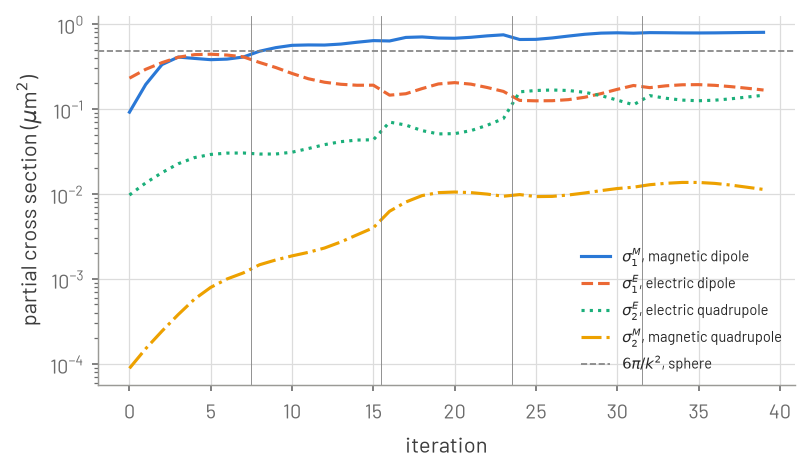

In [4]:
fig, ax = plt.subplots(figsize=(6, 3.2))
ax.plot(md1, label=r"$\sigma^M_1$, magnetic dipole")
ax.plot(ed1, label=r"$\sigma^E_1$, electric dipole")
ax.plot(history[:, 4], label=r"$\sigma^E_2$, electric quadrupole")
ax.plot(history[:, 2], label=r"$\sigma^M_2$, magnetic quadrupole")
ax.axhline(single_channel, color="gray", ls="--", lw=0.8, label=r"$6\pi/k^2$, sphere")
for step in range(8, len(md1), 8):
    ax.axvline(step - 0.5, color="gray", lw=0.4)
ax.set_xlabel("iteration")
ax.set_ylabel(r"partial cross section ($\mu$m$^2$)")
ax.set_yscale("log")
ax.legend(loc="lower right", fontsize=7);

## The design

Slices of the physical density through the cube's centre along the plane $y = 0$ (the plane
of the incident $E$ along $x$ and $k$ along $z$), at the four saved steps: white is material, black air.
Each dot is an element centroid within 0.05 µm of the plane. The design starts as a
uniform grey cube. By step 24 the material has gathered into two plates, one near each face along the
propagation direction $z$, with a few blocks between them, and by step 39 the plates are
nearly solid and the middle is air: two high-index slabs facing the wave, a gap between them
along $z$. Their blocky edges follow the elements of the mesh, not a smooth outline.

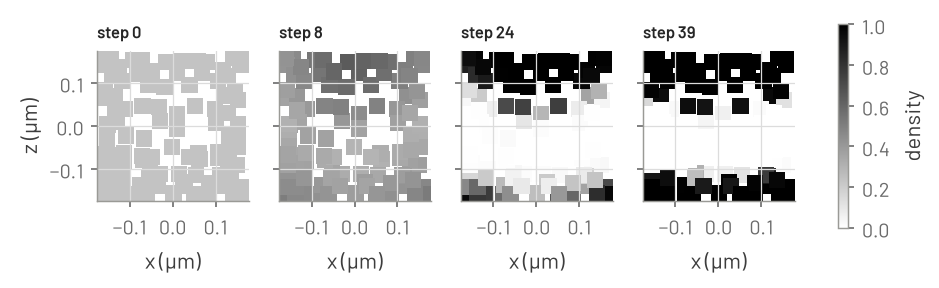

In [5]:
centres = out["centres"] / 1e-6  # m to um
steps = out["snapshot_steps"]
fig, axes = plt.subplots(1, len(steps), figsize=(7.5, 2.2), sharey=True)
near = np.abs(centres[:, 1]) < 0.05
for ax, step, density in zip(axes, steps, out["snapshots"], strict=True):
    shown = ax.scatter(
        centres[near, 0],
        centres[near, 2],
        c=density[near],
        cmap="gray_r",
        vmin=0,
        vmax=1,
        s=60,
        marker="s",
        edgecolors="none",
    )
    ax.set_title(f"step {step}", fontsize=8)
    ax.set_aspect("equal")
    ax.set_xlabel("x (µm)")
axes[0].set_ylabel("z (µm)")
fig.colorbar(shown, ax=axes, label="density", shrink=0.8);

## Checks on the final design

Two checks guard the order-2 design. The final density is solved again at **order 3**
(47 466 unknowns against 16 434 at order 2), and the partial cross sections of the multipoles
are summed and compared with {py:func}`gfem.cross_sections`, which measures the scattering as a power balance
on the truncation layer.

In [6]:
o2, o3 = settings["order2"], settings["order3"]
order_gap = settings["order_gap"]
sum_gap = settings["sum_gap"]
for order, o in (2, o2), (3, o3):
    print(
        f"order {order}: {o['dof']} unknowns, sigma^M_1 = {o['md']:.3f} um^2, "
        f"sigma^E_1 = {o['ed']:.3f} um^2"
    )
print(f"order gap of sigma^M_1: {100 * order_gap:.1f} %")
print(
    f"order 3: sum of the partial cross sections {o3['sum']:.4f} um^2, "
    f"cross_sections {o3['cross_sections']:.4f} um^2"
)
print(f"sum gap: {100 * sum_gap:.2f} %")

order 2: 16434 unknowns, sigma^M_1 = 0.799 um^2, sigma^E_1 = 0.160 um^2
order 3: 47466 unknowns, sigma^M_1 = 0.919 um^2, sigma^E_1 = 0.116 um^2
order gap of sigma^M_1: 14.9 %
order 3: sum of the partial cross sections 1.2022 um^2, cross_sections 1.1924 um^2
sum gap: 0.82 %


The order-3 solve gives $\sigma^M_1 = 0.919$ µm² against 0.799 µm² at order 2: the
order-2 design solves are coarse, 15 % off in the magnetic dipole, and the optimizer has
exploited some of that error. The design still exceeds the sphere's 0.477 µm² at order 3, and the
partial cross sections sum to the scattering cross section to 0.82 %, 1.2022 µm² against
1.1924 µm². Read the design as a shape and the order-3 values as the physics; a
mesh refined around the cube would tighten the first.

## Limits

- **A coarse design mesh.** Order 2 on elements of 0.08 µm makes the optimizer's objective
  15 % lower than the order-3 value of the same design, and the optimized design may exploit
  the discretization. A finer mesh costs memory and time quickly: the page keeps the
  design solves under 30 000 unknowns.
- **One wavelength and one polarization.** The design is optimal for this wave only.
- **A local optimum.** Adam from one start finds a local optimum; another start or
  another $\beta$ schedule gives another design.
- **Lossless, no fabrication constraints.** The filter sets a length scale of about 0.05 µm and nothing
  else; the cube floats in air, with no substrate, which the multipoles refuse.
- **A reference, not a bound.** $6\pi/k^2$ is the single-channel value of a sphere; this design
  exceeds it, and nothing here shows the largest $\sigma^M_1$ a cube can reach.

## How this was run

- The run is [`tools/meta_atom_run.py`](https://github.com/benvial/gfem/blob/main/tools/meta_atom_run.py),
  on the mesh of `tools/meta_atom_mesh.py`. From a clone of the repository,
  `just meta-atom-data` reruns it and rewrites the saved results.
- The numbers are those of the gfem version that ran (printed under "The record"). A later
  gfem does not update them.

## Next

- {doc}`../recipes/multipoles`: the decomposition of a sphere against Mie, Kerker and
  anapole, and what is differentiable.
- {doc}`../recipes/cross-sections`: the power balance the sum is checked against.
- {doc}`metagrating`: the density design with a filter, projection and Adam on a layer.

The numbers this page relies on, checked: the gradient against the difference (under
$10^{-6}$), the order-3 re-solve within 0.45 of the order-2 value, the sum of the
partial cross sections against the cross sections within 0.025, and a gain of
more than 5 over the starting design.

In [7]:
np.testing.assert_array_less(fd_error, 1e-6)
np.testing.assert_array_less(order_gap, 0.45)
np.testing.assert_array_less(sum_gap, 0.025)
np.testing.assert_array_less(5, gain)
wavelength = settings["wavelength_um"]
np.testing.assert_allclose(single_channel, 3 * wavelength**2 / (2 * np.pi))
np.testing.assert_array_less(single_channel, o3["md"])